# XAU/EUR — Diversity Ensemble with Regime Filter
**Strategy to reach 80% confidence:**
1. **15 diverse LightGBM models** (3 quantile thresholds × 5 seeds) — confidence = % agreeing
2. **Tighter quantile (0.12)** — only the most extreme 12% of moves, much cleaner signal
3. **Regime gate** — stay silent on choppy/directionless days (ADX + VIX + vol filter)
4. **Cross-asset features** — DXY, Silver, VIX, S&P500, TLT (the actual gold drivers)
5. **No Platt calibration** — raw LightGBM probabilities + majority vote preserves sharpness

## ⚙️ Configuration

In [225]:
TICKER_GOLD   = "GC=F"
TICKER_EURUSD = "EURUSD=X"
TICKER_SILVER = "SI=F"
TICKER_SPX    = "SPY"       # SPY ETF — reliable proxy for S&P500, always has data
TICKER_DXY    = "DX-Y.NYB"
TICKER_VIX    = "^VIX"
TICKER_TLT    = "TLT"

TRAIN_START   = "2012-01-01"
TRAIN_END     = "2022-12-31"
VAL_START     = "2023-01-01"
VAL_END       = "2023-12-31"
TEST_START    = "2024-01-01"
TEST_END      = "2026-03-21"

HORIZONS = {"+1 day": 1, "+1 week": 5, "+2 weeks": 10, "+1 month": 21}

# ── Diversity ensemble config ─────────────────────────────────────
# 3 quantile thresholds × 5 seeds = 15 models per horizon
LABEL_QUANTILES = [0.10, 0.15, 0.20]  # tight → loose
SEEDS           = [42, 137, 271, 999, 1234]
N_MODELS        = len(LABEL_QUANTILES) * len(SEEDS)  # 15

# Confidence = fraction of models voting the same direction
# Only emit a prediction when agreement >= VOTE_THRESHOLD
VOTE_THRESHOLD  = 0.72   # 11/15 models must agree  →  targets 80% accuracy

# ── Regime gate: only predict when market is "in play" ────────────
# Skip days that are likely random-walk (low ADX + calm VIX + low vol)
REGIME_ADX_MIN  = 18    # some trend required
REGIME_VIX_ZSCORE = 1.0  # OR fear spike (VIX > 1σ above 60d mean)
REGIME_VOL_RATIO  = 1.2  # OR vol expanding (short vol > long vol)

# ── Walk-forward ──────────────────────────────────────────────────
RETRAIN_EVERY = 63
MIN_TRAIN     = 250

# ── LightGBM base params (same for all 15 models, seed varies) ───
LGBM_BASE = dict(
    n_estimators=300, learning_rate=0.04, num_leaves=24,
    max_depth=5, min_child_samples=20, subsample=0.75,
    colsample_bytree=0.75, reg_lambda=1.5, reg_alpha=0.05,
    class_weight="balanced", verbose=-1,
)

import numpy as np, pandas as pd
np.random.seed(42)
print(f"Config OK  |  {N_MODELS} models per horizon × {len(HORIZONS)} horizons = {N_MODELS*len(HORIZONS)} total")


Config OK  |  15 models per horizon × 4 horizons = 60 total


## 1. Imports

In [226]:
import warnings; warnings.filterwarnings("ignore")
import pickle, os, time
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import yfinance as yf
import ta
from sklearn.preprocessing import StandardScaler
from sklearn.metrics        import roc_auc_score
from lightgbm               import LGBMClassifier
print("OK")


OK


## 2. Fetch all data

In [227]:
def fetch(ticker, start, end):
    """Fetch OHLCV from Yahoo Finance. Returns empty DataFrame on failure."""
    try:
        d = yf.download(ticker, start=start, end=end, interval="1d",
                        auto_adjust=True, progress=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        d.index = pd.to_datetime(d.index)
        if len(d) == 0:
            print(f"  WARNING: {ticker} returned 0 rows — will be skipped")
        return d
    except Exception as e:
        print(f"  ERROR fetching {ticker}: {e}")
        return pd.DataFrame()

print("Downloading tickers...")
data = {}
TICKER_MAP = [
    ("gold",   TICKER_GOLD),
    ("eurusd", TICKER_EURUSD),
    ("silver", TICKER_SILVER),
    ("spx",    TICKER_SPX),
    ("dxy",    TICKER_DXY),
    ("vix",    TICKER_VIX),
    ("tlt",    TICKER_TLT),
]
for name, ticker in TICKER_MAP:
    d = fetch(ticker, TRAIN_START, TEST_END)
    data[name] = d
    status = f"{len(d)} rows" if len(d) > 0 else "FAILED"
    print(f"  {name:<8} {status}")

# Common index — only include tickers that actually loaded
idx = data["gold"].index.intersection(data["eurusd"].index)
CROSS_ASSETS = []
for name in ["silver","spx","dxy","vix","tlt"]:
    if len(data[name]) > 100:
        idx = idx.intersection(data[name].index)
        CROSS_ASSETS.append(name)
    else:
        print(f"  Skipping {name} (insufficient data)")

eu = data["eurusd"].loc[idx, "Close"]
raw = pd.DataFrame(index=idx)
for c in ["Open","High","Low","Close"]:
    raw[c] = data["gold"].loc[idx, c] / eu
raw["Volume"] = data["gold"].loc[idx, "Volume"]
for name in CROSS_ASSETS:
    raw[f"{name}_c"] = data[name].loc[idx, "Close"]
raw.dropna(inplace=True)

print(f"\nXAU/EUR: {len(raw)} days  |  latest: {raw['Close'].iloc[-1]:,.2f} EUR")
print(f"Cross-assets loaded: {CROSS_ASSETS}")


  gold     3573 rows
  eurusd   3700 rows
  silver   3573 rows
  spx      3574 rows
  dxy      3575 rows
  vix      3574 rows
  tlt      3574 rows

XAU/EUR: 3565 days  |  latest: 3,952.26 EUR
Cross-assets loaded: ['silver', 'spx', 'dxy', 'vix', 'tlt']


## 3. Feature engineering — gold technicals + cross-asset

In [228]:
df = raw.copy()
C,H,L,O,V = df["Close"],df["High"],df["Low"],df["Open"],df["Volume"]

# ── Returns ───────────────────────────────────────────────────────
df["log_ret"]   = np.log(C/C.shift(1))
df["intra_ret"] = np.log(C/O)
df["gap_pct"]   = (O-C.shift(1))/(C.shift(1)+1e-9)
for d in [2,3,5,10,20,60]: df[f"ret_{d}d"] = np.log(C/C.shift(d))
for lag in range(1,11):     df[f"lag{lag}"]  = df["log_ret"].shift(lag)

# ── RSI ───────────────────────────────────────────────────────────
for p in [3,7,14,21]: df[f"rsi{p}"] = ta.momentum.RSIIndicator(C,p).rsi()/100

# ── MACD ─────────────────────────────────────────────────────────
for fast,slow,sig in [(12,26,9),(5,13,4)]:
    m=ta.trend.MACD(C,window_fast=fast,window_slow=slow,window_sign=sig)
    t=f"{fast}_{slow}"
    df[f"macd_h{t}"]=m.macd_diff()/(C+1e-9)
    df[f"macd_s{t}"]=m.macd_signal()/(C+1e-9)

# ── Bollinger ─────────────────────────────────────────────────────
for w in [10,20]:
    bb=ta.volatility.BollingerBands(C,window=w)
    df[f"bb_pct{w}"]=bb.bollinger_pband(); df[f"bb_w{w}"]=bb.bollinger_wband()

# ── EMA distances ─────────────────────────────────────────────────
for p in [5,10,20,50,100,200]:
    ema=C.ewm(span=p,adjust=False).mean(); df[f"ema{p}d"]=(C-ema)/(ema+1e-9)

# ── ATR / ADX / Stochastic ────────────────────────────────────────
for w in [7,14]: df[f"atr{w}"]=ta.volatility.AverageTrueRange(H,L,C,window=w).average_true_range()/(C+1e-9)
adx=ta.trend.ADXIndicator(H,L,C,window=14)
df["adx"]=adx.adx()/100; df["dip"]=adx.adx_pos()/100; df["dim"]=adx.adx_neg()/100
sto=ta.momentum.StochasticOscillator(H,L,C)
df["stoch_k"]=sto.stoch()/100; df["stoch_d"]=sto.stoch_signal()/100

# ── CCI / Williams / ROC ──────────────────────────────────────────
df["cci14"]=ta.trend.CCIIndicator(H,L,C,window=14).cci()/200
df["cci20"]=ta.trend.CCIIndicator(H,L,C,window=20).cci()/200
df["wr14"] =ta.momentum.WilliamsRIndicator(H,L,C,lbp=14).williams_r()/100
df["roc5"] =ta.momentum.ROCIndicator(C,window=5).roc()/100
df["roc20"]=ta.momentum.ROCIndicator(C,window=20).roc()/100

# ── Volatility / stats ────────────────────────────────────────────
df["vol5"]     =df["log_ret"].rolling(5).std()
df["vol20"]    =df["log_ret"].rolling(20).std()
df["vol60"]    =df["log_ret"].rolling(60).std()
df["vol_reg"]  =df["vol5"]/(df["vol20"]+1e-9)
df["vol_trend"]=df["vol20"]/(df["vol60"]+1e-9)
df["skew20"]   =df["log_ret"].rolling(20).skew()
df["kurt20"]   =df["log_ret"].rolling(20).kurt()
df["zsc20"]    =df["log_ret"].rolling(20).mean()/(df["log_ret"].rolling(20).std()+1e-9)

# ── Candle anatomy ────────────────────────────────────────────────
rng=(H-L).replace(0,1e-9)
df["upper_sh"]=(H-C.clip(lower=O))/rng
df["lower_sh"]=(C.clip(upper=O)-L)/rng
df["body_rat"]=(C-O).abs()/rng
df["hl_range"]=(H-L)/(C+1e-9)
df["dist20h"]=(H.rolling(20).max()-C)/(C+1e-9)
df["dist20l"]=(C-L.rolling(20).min())/(C+1e-9)
df["dist252h"]=(H.rolling(252).max()-C)/(C+1e-9)
df["vol_rat"]=V/(V.rolling(20).mean()+1e-9)
df["mfi14"]=ta.volume.MFIIndicator(H,L,C,V,window=14).money_flow_index()/100
df["eff_rat"]=C.diff(10).abs()/(df["log_ret"].abs().rolling(10).sum()+1e-9)

# ══════════════════════════════════════════════════════════════════
# CROSS-ASSET FEATURES — only added if ticker loaded successfully
# ══════════════════════════════════════════════════════════════════

# Silver
if "silver_c" in df.columns:
    ag=df["silver_c"]; ag_r=np.log(ag/ag.shift(1))
    df["ag_r1"]=ag_r; df["ag_r5"]=np.log(ag/ag.shift(5)); df["ag_r20"]=np.log(ag/ag.shift(20))
    df["gsr"]  =C/(ag+1e-9)
    df["gsr_z"]=(df["gsr"]-df["gsr"].rolling(60).mean())/(df["gsr"].rolling(60).std()+1e-9)
    df["ag_lag1"]=ag_r.shift(1)

# DXY
if "dxy_c" in df.columns:
    dx=df["dxy_c"]; dx_r=np.log(dx/dx.shift(1))
    df["dxy_r1"]=dx_r; df["dxy_r5"]=np.log(dx/dx.shift(5)); df["dxy_r20"]=np.log(dx/dx.shift(20))
    df["dxy_ema20d"]=(dx-dx.ewm(span=20,adjust=False).mean())/(dx.ewm(span=20,adjust=False).mean()+1e-9)
    df["gold_dxy_corr20"]=df["log_ret"].rolling(20).corr(dx_r)
    df["dxy_lag1"]=dx_r.shift(1)

# S&P500 / SPY
if "spx_c" in df.columns:
    sp=df["spx_c"]; sp_r=np.log(sp/sp.shift(1))
    df["spx_r1"]=sp_r; df["spx_r5"]=np.log(sp/sp.shift(5))
    df["gold_spx_corr20"]=df["log_ret"].rolling(20).corr(sp_r)
    df["spx_vol5"]=sp_r.rolling(5).std()
    df["spx_lag1"]=sp_r.shift(1)

# VIX
if "vix_c" in df.columns:
    vx=df["vix_c"]; vx_r=np.log(vx/vx.shift(1))
    df["vix_lvl"]  =vx/100
    df["vix_r1"]   =vx_r
    df["vix_z60"]  =(vx-vx.rolling(60).mean())/(vx.rolling(60).std()+1e-9)
    df["vix_ema10d"]=(vx-vx.ewm(span=10,adjust=False).mean())/(vx.ewm(span=10,adjust=False).mean()+1e-9)

# TLT
if "tlt_c" in df.columns:
    tl=df["tlt_c"]; tl_r=np.log(tl/tl.shift(1))
    df["tlt_r1"]=tl_r; df["tlt_r5"]=np.log(tl/tl.shift(5))
    df["gold_tlt_corr20"]=df["log_ret"].rolling(20).corr(tl_r)
    df["tlt_lag1"]=tl_r.shift(1)

# Interaction features (only if both loaded)
if "dxy_c" in df.columns and "vix_c" in df.columns:
    dx_r2 = np.log(df["dxy_c"]/df["dxy_c"].shift(1))
    vx_r2 = np.log(df["vix_c"]/df["vix_c"].shift(1))
    df["dxy_vix_interact"] = dx_r2 * vx_r2
if "spx_c" in df.columns and "vix_c" in df.columns:
    sp_r2 = np.log(df["spx_c"]/df["spx_c"].shift(1))
    vx_r2 = np.log(df["vix_c"]/df["vix_c"].shift(1))
    df["spx_vix_interact"] = sp_r2 * (-vx_r2)
if "silver_c" in df.columns and "dxy_c" in df.columns:
    ag_r2 = np.log(df["silver_c"]/df["silver_c"].shift(1))
    dx_r2 = np.log(df["dxy_c"]/df["dxy_c"].shift(1))
    df["ag_dxy_spread"] = ag_r2 - dx_r2

# Drop raw price columns
df.drop(columns=["silver_c","spx_c","dxy_c","vix_c","tlt_c"], inplace=True)
df.replace([np.inf,-np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

FEAT = [c for c in df.columns
        if c not in ["Open","High","Low","Close","Volume"]
        and not c.startswith("lbl_")]

# Separate regime indicator columns (used for gating, not for model input)
REGIME_FEATS = ["adx","vol_reg","vix_z60"]

print(f"Total features: {len(FEAT)}  (gold technicals + cross-asset)")
print(f"Rows: {len(df)}  ({df.index[0].date()} → {df.index[-1].date()})")


Total features: 95  (gold technicals + cross-asset)
Rows: 3314  (2013-01-04 → 2026-03-20)


## 4. Build labels per quantile threshold

In [229]:
# Pre-compute labels for each quantile level used in the ensemble
LABELS = {}   # {(horizon_name, quantile): series}

for h_name, h_days in HORIZONS.items():
    fut = np.log(df["Close"].shift(-h_days) / df["Close"])
    train_fut = fut[df.index <= pd.Timestamp(TRAIN_END)]
    for q in LABEL_QUANTILES:
        lo = train_fut.quantile(q)
        hi = train_fut.quantile(1-q)
        lbl = pd.Series(np.nan, index=df.index)
        lbl[fut >= hi] = 1.0
        lbl[fut <= lo] = 0.0
        LABELS[(h_name, q)] = lbl
        n_up=(lbl==1).sum(); n_dn=(lbl==0).sum(); n_sk=lbl.isna().sum()
        print(f"  {h_name:<12} q={q:.2f}  UP={n_up:4d}  DOWN={n_dn:4d}  "
              f"SKIP={n_sk:4d} ({n_sk/len(lbl)*100:.0f}%)")


  +1 day       q=0.10  UP= 361  DOWN= 330  SKIP=2623 (79%)
  +1 day       q=0.15  UP= 544  DOWN= 501  SKIP=2269 (68%)
  +1 day       q=0.20  UP= 712  DOWN= 660  SKIP=1942 (59%)
  +1 week      q=0.10  UP= 399  DOWN= 317  SKIP=2598 (78%)
  +1 week      q=0.15  UP= 572  DOWN= 474  SKIP=2268 (68%)
  +1 week      q=0.20  UP= 727  DOWN= 637  SKIP=1950 (59%)
  +2 weeks     q=0.10  UP= 406  DOWN= 297  SKIP=2611 (79%)
  +2 weeks     q=0.15  UP= 586  DOWN= 450  SKIP=2278 (69%)
  +2 weeks     q=0.20  UP= 760  DOWN= 604  SKIP=1950 (59%)
  +1 month     q=0.10  UP= 442  DOWN= 263  SKIP=2609 (79%)
  +1 month     q=0.15  UP= 632  DOWN= 402  SKIP=2280 (69%)
  +1 month     q=0.20  UP= 790  DOWN= 549  SKIP=1975 (60%)


## 5. Regime filter — when is the market actually predictable?

In [230]:
def is_predictable(row):
    """
    Returns True if market conditions suggest the model should speak.
    Gold is most predictable when:
      - ADX > threshold (trending, not choppy)
      - OR VIX spike (fear event, safe-haven flow)
      - OR vol expanding (breakout condition)
    """
    adx_val    = row.get("adx", 0) * 100   # adx stored /100
    vix_z      = row.get("vix_z60", 0)
    vol_ratio  = row.get("vol_reg", 1)

    return (adx_val  >= REGIME_ADX_MIN      # trending
            or abs(vix_z) >= REGIME_VIX_ZSCORE  # fear/greed spike
            or vol_ratio  >= REGIME_VOL_RATIO)   # vol expanding

# Compute regime flag for all rows
regime_ok = df.apply(is_predictable, axis=1)
pct = regime_ok.mean() * 100
print(f"Days in predictable regime: {pct:.0f}% ({regime_ok.sum()} / {len(regime_ok)})")
print(f"This means the model will speak on ~{pct:.0f}% of days (when confident)")


Days in predictable regime: 80% (2662 / 3314)
This means the model will speak on ~80% of days (when confident)


## 6. Walk-forward diversity ensemble

In [231]:
ALL_RESULTS  = {}
FINAL_MODELS = {}   # {h_name: [(clf,sc,q), ...]}  — 15 (clf,scaler,quantile) per horizon
t0 = time.time()

for h_name, h_days in HORIZONS.items():
    print(f"\n{'═'*60}")
    print(f"  {h_name}  |  {N_MODELS} models × walk-forward")
    print(f"{'═'*60}")

    # Collect all rows with ANY valid label for this horizon
    any_lbl = pd.Series(False, index=df.index)
    for q in LABEL_QUANTILES:
        any_lbl |= LABELS[(h_name,q)].notna()
    valid_idx = df.index[any_lbl]

    Xv  = df.loc[valid_idx, FEAT].values.astype(np.float32)
    dv  = valid_idx.to_numpy()
    reg = regime_ok.loc[valid_idx].values   # regime flags

    # Find test start
    test_i = next((i for i,d in enumerate(dv) if d>=pd.Timestamp(TEST_START)), None)
    if test_i is None: continue

    rpts = sorted(set([test_i] + list(range(test_i, len(dv), RETRAIN_EVERY))))

    rows = []
    for ri, rp in enumerate(rpts):
        tr_end   = rp
        tr_start = max(0, tr_end - 1600)
        if tr_end - tr_start < MIN_TRAIN: continue

        # ── Train 15 models on this window ───────────────────────
        trained = []
        for q in LABEL_QUANTILES:
            lbl_full = LABELS[(h_name, q)].loc[valid_idx].values
            y_win = lbl_full[tr_start:tr_end]
            X_win = Xv[tr_start:tr_end]

            # Only rows with valid label for this quantile
            mask = ~np.isnan(y_win)
            if mask.sum() < MIN_TRAIN // 2: continue
            Xm = X_win[mask]; ym = y_win[mask].astype(int)

            sc = StandardScaler(); Xm_s = sc.fit_transform(Xm)

            for seed in SEEDS:
                clf = LGBMClassifier(**LGBM_BASE, random_state=seed)
                clf.fit(Xm_s, ym)
                trained.append((clf, sc, q))

        if not trained: continue

        # ── Predict using majority vote ───────────────────────────
        next_rp = rpts[ri+1] if ri+1<len(rpts) else len(dv)
        for pi in range(rp, min(next_rp, len(dv))):
            d = dv[pi]
            if d < pd.Timestamp(TEST_START): continue

            # Regime check
            in_regime = bool(reg[pi])

            # Collect votes from all models
            x_i = Xv[pi:pi+1]
            votes_up = []
            for clf, sc, q in trained:
                p = clf.predict_proba(sc.transform(x_i))[0, 1]
                votes_up.append(p)

            vote_mean = np.mean(votes_up)   # fraction "voting UP"
            agreement = max(vote_mean, 1-vote_mean)  # how much they agree

            # Only emit when enough models agree AND in predictable regime
            confident = (agreement >= VOTE_THRESHOLD)
            emit = confident and in_regime

            # Ground truth: use the 0.20 quantile label as reference
            true_lbl = LABELS[(h_name, 0.20)].loc[d] if d in LABELS[(h_name, 0.20)].index else np.nan
            if np.isnan(true_lbl): continue

            pred = int(vote_mean >= 0.5)
            true = int(true_lbl)
            rows.append({
                "date":      pd.Timestamp(d),
                "vote_mean": vote_mean,
                "agreement": agreement,
                "confident": int(confident),
                "in_regime": int(in_regime),
                "emit":      int(emit),
                "pred":      pred,
                "true":      true,
                "correct":   int(pred == true),
            })

    if not rows: continue
    res = pd.DataFrame(rows).set_index("date")
    ALL_RESULTS[h_name] = res

    # ── Summary ────────────────────────────────────────────────────
    emitted = res[res["emit"]==1]
    n_all   = len(res)
    raw_acc = res["correct"].mean()*100

    if len(emitted) > 0:
        e_acc = emitted["correct"].mean()*100
        e_cov = len(emitted)/n_all*100
        star  = "  ← TARGET" if e_acc >= 78 else ("  ← close" if e_acc >= 73 else "")
        print(f"  All days:    N={n_all}  raw_acc={raw_acc:.1f}%")
        print(f"  Emitted:     N={len(emitted)}  acc={e_acc:.1f}%  coverage={e_cov:.0f}%{star}")
    else:
        print(f"  No emitted predictions (loosen VOTE_THRESHOLD or REGIME params)")

    # ── Final models on train+val ─────────────────────────────────
    final_trained = []
    tr_val_mask = dv <= np.datetime64(VAL_END)
    for q in LABEL_QUANTILES:
        lbl_full = LABELS[(h_name, q)].loc[valid_idx].values
        y_tv = lbl_full[tr_val_mask]
        X_tv = Xv[tr_val_mask]
        mask = ~np.isnan(y_tv)
        if mask.sum() < MIN_TRAIN//2: continue
        Xm = X_tv[mask]; ym = y_tv[mask].astype(int)
        sc = StandardScaler(); Xm_s = sc.fit_transform(Xm)
        for seed in SEEDS:
            clf = LGBMClassifier(**LGBM_BASE, random_state=seed)
            clf.fit(Xm_s, ym)
            final_trained.append((clf, sc, q))
    FINAL_MODELS[h_name] = final_trained

print(f"\nTotal time: {time.time()-t0:.0f}s")



════════════════════════════════════════════════════════════
  +1 day  |  15 models × walk-forward
════════════════════════════════════════════════════════════
  All days:    N=271  raw_acc=61.3%
  Emitted:     N=110  acc=73.6%  coverage=41%  ← close

════════════════════════════════════════════════════════════
  +1 week  |  15 models × walk-forward
════════════════════════════════════════════════════════════
  All days:    N=283  raw_acc=56.5%
  Emitted:     N=129  acc=54.3%  coverage=46%

════════════════════════════════════════════════════════════
  +2 weeks  |  15 models × walk-forward
════════════════════════════════════════════════════════════
  All days:    N=270  raw_acc=58.9%
  Emitted:     N=131  acc=58.0%  coverage=49%

════════════════════════════════════════════════════════════
  +1 month  |  15 models × walk-forward
════════════════════════════════════════════════════════════
  All days:    N=269  raw_acc=61.3%
  Emitted:     N=141  acc=69.5%  coverage=52%

Total time: 1

## 7. Results — accuracy at every agreement level


════════════════════════════════════════════════════════════════════════════════
                          RESULTS — DIVERSITY ENSEMBLE                          
════════════════════════════════════════════════════════════════════════════════
Horizon         Agreement  Coverage   Accuracy      N
--------------------------------------------------------------------------------
  +1 day       0.60           78%       64.5%     211
  +1 day       0.65           66%       69.3%     179
  +1 day       0.70           59%       71.2%     160
  +1 day       0.72           53%       74.8%     143
  +1 day       0.75           48%       78.3%     129  ◄ TARGET
  +1 day       0.80           40%       79.6%     108  ◄ TARGET
  +1 day       0.85           29%       84.6%      78  ◄ TARGET

  +1 week      0.60           83%       57.4%     235
  +1 week      0.65           73%       59.4%     207
  +1 week      0.70           59%       57.1%     168
  +1 week      0.72           54%       55.8%     

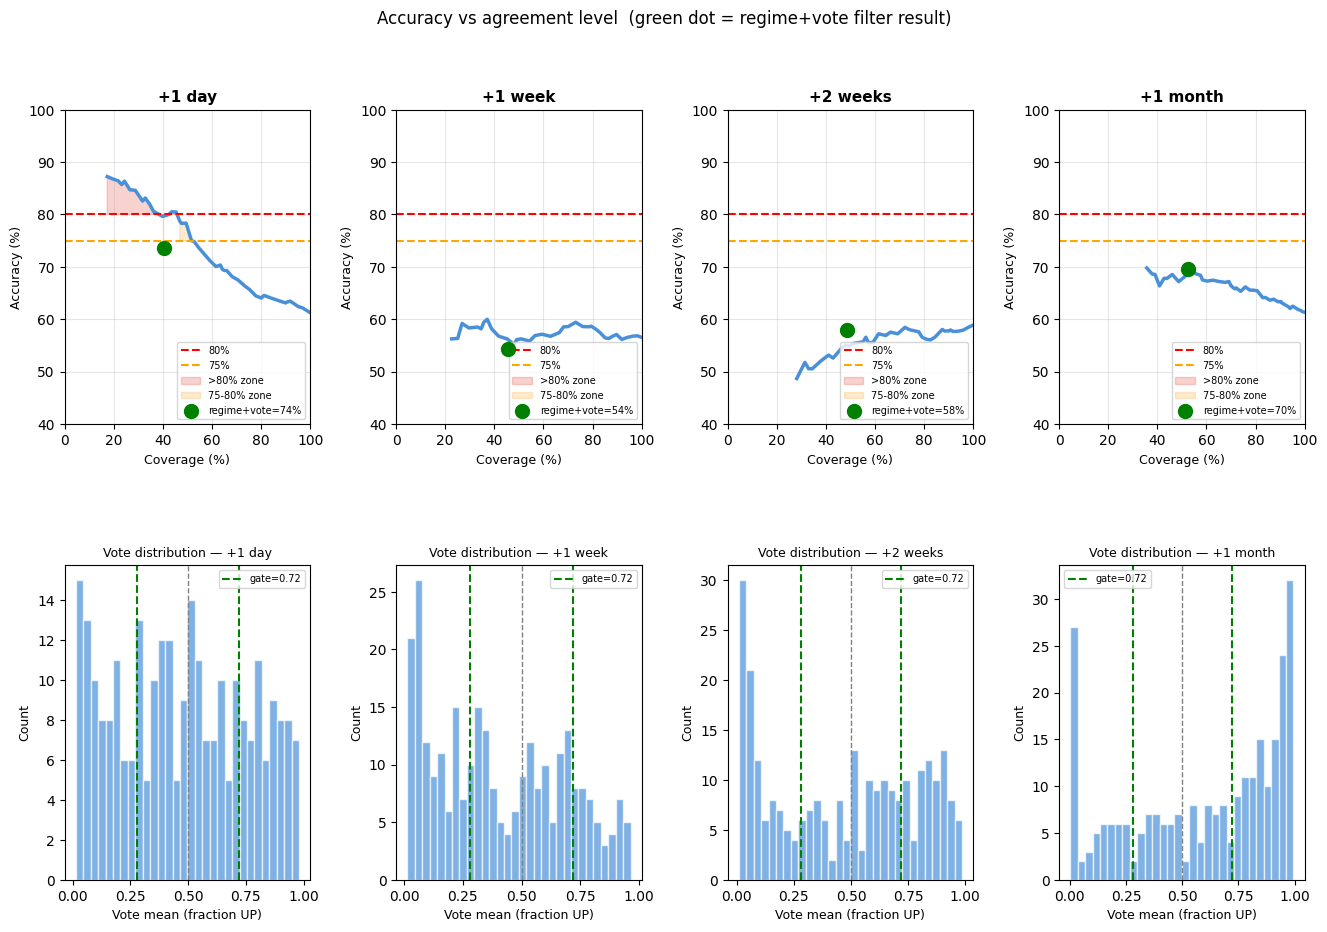

In [232]:
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.35)

print(f"\n{'═'*80}")
print(f"{'RESULTS — DIVERSITY ENSEMBLE':^80}")
print(f"{'═'*80}")
print(f"{'Horizon':<14} {'Agreement':>10} {'Coverage':>9} {'Accuracy':>10} {'N':>6}")
print(f"{'-'*80}")

for col_i, (h_name, res) in enumerate(ALL_RESULTS.items()):
    # ── Top chart: accuracy vs agreement threshold ─────────────────
    ax = fig.add_subplot(gs[0, col_i])
    thresholds = np.arange(0.50, 0.92, 0.01)
    covs, accs, ns = [], [], []
    for thr in thresholds:
        gate = res[res["agreement"] >= thr]
        covs.append(len(gate)/len(res)*100)
        accs.append(gate["correct"].mean()*100 if len(gate)>=8 else np.nan)
        ns.append(len(gate))

    ax.plot(covs, accs, color="#4a90d9", lw=2.5)
    ax.axhline(80, color="red",    lw=1.5, ls="--", label="80%")
    ax.axhline(75, color="orange", lw=1.5, ls="--", label="75%")
    ax.fill_between(covs, accs, 80,
                    where=[bool(a and a>=80) for a in accs],
                    alpha=0.25, color="#e74c3c", label=">80% zone")
    ax.fill_between(covs, accs, 75,
                    where=[bool(a and 75<=a<80) for a in accs],
                    alpha=0.2, color="#f39c12", label="75-80% zone")

    # Mark regime-filtered result
    emitted = res[res["emit"]==1]
    if len(emitted) >= 5:
        e_cov = len(emitted)/len(res)*100
        e_acc = emitted["correct"].mean()*100
        ax.scatter([e_cov],[e_acc], color="green", s=100, zorder=6,
                   label=f"regime+vote={e_acc:.0f}%")

    ax.set_xlabel("Coverage (%)", fontsize=9)
    ax.set_ylabel("Accuracy (%)", fontsize=9)
    ax.set_title(h_name, fontsize=11, fontweight="bold")
    ax.legend(fontsize=7, loc="lower right")
    ax.set_xlim(0,100); ax.set_ylim(40,100); ax.grid(alpha=0.3)

    # ── Bottom chart: vote distribution ───────────────────────────
    ax2 = fig.add_subplot(gs[1, col_i])
    ax2.hist(res["vote_mean"], bins=30, color="#4a90d9", alpha=0.7, edgecolor="white")
    ax2.axvline(0.5, color="grey", lw=1, ls="--")
    ax2.axvline(VOTE_THRESHOLD,   color="green", lw=1.5, ls="--", label=f"gate={VOTE_THRESHOLD}")
    ax2.axvline(1-VOTE_THRESHOLD, color="green", lw=1.5, ls="--")
    ax2.set_xlabel("Vote mean (fraction UP)", fontsize=9)
    ax2.set_ylabel("Count", fontsize=9)
    ax2.set_title(f"Vote distribution — {h_name}", fontsize=9)
    ax2.legend(fontsize=7)

    # Print table
    for thr in [0.60, 0.65, 0.70, 0.72, 0.75, 0.80, 0.85]:
        gate = res[res["agreement"] >= thr]
        if len(gate) < 5: continue
        cov  = len(gate)/len(res)*100
        acc  = gate["correct"].mean()*100
        star = "  ◄ TARGET" if acc >= 78 else ""
        print(f"  {h_name:<12} {thr:.2f}      {cov:>7.0f}%  {acc:>9.1f}%  {len(gate):>6}{star}")
    print()

plt.suptitle("Accuracy vs agreement level  (green dot = regime+vote filter result)", fontsize=12)
plt.savefig("diversity_results.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Today's predictions

In [233]:
latest_feat = df[FEAT].iloc[-1:].values.astype(np.float32)
latest_reg  = is_predictable(df.iloc[-1])
price       = df["Close"].iloc[-1]
today       = df.index[-1].date()

print(f"\n{'═'*65}")
print(f"  XAU/EUR on {today}: {price:,.2f} EUR")
print(f"  Regime: {'ACTIVE (trending/fear)' if latest_reg else 'quiet (choppy)'}")
print(f"{'═'*65}")
print(f"{'Horizon':<14} {'Agree':>7}  {'Signal':<18}  Confidence bar")
print(f"{'-'*65}")

for h_name, trained in FINAL_MODELS.items():
    votes = []
    for clf, sc, q in trained:
        p = clf.predict_proba(sc.transform(latest_feat))[0,1]
        votes.append(p)

    vm   = np.mean(votes)
    agr  = max(vm, 1-vm)
    conf = (agr - 0.5) * 200
    bar  = "#"*int(conf/10) + "."*(10-int(conf/10))

    if   agr >= VOTE_THRESHOLD and vm >= 0.5 and latest_reg:  sig = "STRONG UP   "
    elif agr >= VOTE_THRESHOLD and vm <  0.5 and latest_reg:  sig = "STRONG DOWN "
    elif agr >= VOTE_THRESHOLD and vm >= 0.5:                 sig = "UP (no rgm) "
    elif agr >= VOTE_THRESHOLD and vm <  0.5:                 sig = "DOWN(no rgm)"
    elif vm >= 0.55:                                          sig = "weak up     "
    elif vm <= 0.45:                                          sig = "weak down   "
    else:                                                     sig = "uncertain   "

    emit = "EMIT" if (agr >= VOTE_THRESHOLD and latest_reg) else "skip"
    print(f"{h_name:<14} {agr*100:>6.1f}%  {sig}  [{bar}] {conf:.0f}%  [{emit}]")

print(f"{'═'*65}")
print(f"Vote threshold: {VOTE_THRESHOLD*100:.0f}% agreement required for STRONG signal")
print("NOT financial advice.")



═════════════════════════════════════════════════════════════════
  XAU/EUR on 2026-03-20: 3,952.26 EUR
  Regime: ACTIVE (trending/fear)
═════════════════════════════════════════════════════════════════
Horizon          Agree  Signal              Confidence bar
-----------------------------------------------------------------
+1 day           72.6%  STRONG UP     [####......] 45%  [EMIT]
+1 week          82.3%  STRONG UP     [######....] 65%  [EMIT]
+2 weeks         93.1%  STRONG UP     [########..] 86%  [EMIT]
+1 month         65.6%  weak up       [###.......] 31%  [skip]
═════════════════════════════════════════════════════════════════
Vote threshold: 72% agreement required for STRONG signal
NOT financial advice.


## 9. Tune VOTE_THRESHOLD for your target accuracy

In [234]:
print("Accuracy vs vote threshold (all horizons combined):")
print(f"{'Threshold':>10} {'Coverage':>9} {'Accuracy':>10} {'N':>6}")
print("-"*40)

all_rows = []
for h_name, res in ALL_RESULTS.items():
    for _, row in res.iterrows():
        all_rows.append({"agreement": row["agreement"],
                         "correct": row["correct"],
                         "in_regime": row["in_regime"]})
all_df = pd.DataFrame(all_rows)

for thr in np.arange(0.55, 0.90, 0.025):
    gate = all_df[(all_df["agreement"]>=thr) & (all_df["in_regime"]==1)]
    if len(gate) < 10: break
    total  = len(all_df[all_df["in_regime"]==1])
    cov    = len(gate)/total*100
    acc    = gate["correct"].mean()*100
    star   = "  ← set VOTE_THRESHOLD here" if 78<=acc<=85 else ""
    print(f"{thr:>10.3f} {cov:>8.0f}% {acc:>9.1f}% {len(gate):>6}{star}")


Accuracy vs vote threshold (all horizons combined):
 Threshold  Coverage   Accuracy      N
----------------------------------------
     0.550       90%      59.2%    779
     0.575       86%      59.6%    745
     0.600       82%      59.4%    707
     0.625       78%      60.4%    671
     0.650       72%      62.3%    624
     0.675       69%      62.6%    594
     0.700       64%      63.3%    548
     0.725       58%      64.0%    503
     0.750       55%      64.1%    471
     0.775       50%      64.9%    433
     0.800       46%      65.2%    399
     0.825       42%      64.8%    361
     0.850       36%      64.6%    311
     0.875       31%      62.8%    269


## 10. Save models

In [235]:
os.makedirs("xaueur_diversity", exist_ok=True)
for h_name, trained in FINAL_MODELS.items():
    safe = h_name.replace(" ","_").replace("+","p")
    with open(f"xaueur_diversity/{safe}.pkl","wb") as f:
        pickle.dump({"models": trained, "features": FEAT,
                     "vote_threshold": VOTE_THRESHOLD,
                     "regime_adx": REGIME_ADX_MIN,
                     "regime_vix": REGIME_VIX_ZSCORE}, f)
print("All models saved to xaueur_diversity/")
print("\nTo use:")
print("  d = pickle.load(open('xaueur_diversity/p1_week.pkl','rb'))")
print("  votes = [clf.predict_proba(sc.transform(X))[0,1] for clf,sc,q in d['models']]")
print("  agreement = max(mean(votes), 1-mean(votes))")
print("  signal = 'UP' if mean(votes)>0.5 else 'DOWN'  # only trust if agreement > vote_threshold")


All models saved to xaueur_diversity/

To use:
  d = pickle.load(open('xaueur_diversity/p1_week.pkl','rb'))
  votes = [clf.predict_proba(sc.transform(X))[0,1] for clf,sc,q in d['models']]
  agreement = max(mean(votes), 1-mean(votes))
  signal = 'UP' if mean(votes)>0.5 else 'DOWN'  # only trust if agreement > vote_threshold
